# DS471 Machine Learning Project: Dry Bean Classification

This notebook follows the project stages: data preparation, data splitting, model selection, training and hyperparameter optimization, and evaluation.

# Stage 1: Data Preparation
## 1.1 Loading the data

The dataset has 13,611 samples and 16 numerical features, plus the target column Class (7 bean types).

In [35]:
# Download the dataset automatically
import os, glob, zipfile, urllib.request

FILE = "Dry_Bean_Dataset.xlsx"

# The notebook tries these sources in order and uses the first one that works
URLS = [
    "https://archive.ics.uci.edu/static/public/602/dry+bean+dataset.zip",

]

def download(url):
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req) as r:
        data = r.read()
    if url.endswith(".zip"):
        with open("dry_bean.zip", "wb") as f:
            f.write(data)
        with zipfile.ZipFile("dry_bean.zip") as z:
            z.extractall("dry_bean_data")
        found = glob.glob("dry_bean_data/**/Dry_Bean_Dataset.xlsx", recursive=True)[0]
        os.replace(found, FILE)
    else:
        with open(FILE, "wb") as f:
            f.write(data)

if not os.path.exists(FILE):
    for url in URLS:
        try:
            download(url)
            print("Downloaded from:", url)
            break
        except Exception as e:
            print("Failed:", url, "->", e)
    else:
        raise RuntimeError("Could not download the dataset. Upload Dry_Bean_Dataset.xlsx manually.")

print("Dataset ready:", FILE)


Dataset ready: Dry_Bean_Dataset.xlsx


In [2]:
# Load the data and look at the first rows
import pandas as pd

df = pd.read_excel("Dry_Bean_Dataset.xlsx")
print(df.shape)
df.head()

(13611, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


## 1.2 Data types, missing values and duplicates

There are no missing values. We found 68 duplicate rows, all from Horoz. We removed them because they were identical in all 16 features and could appear in both the training and test sets. The dataset now has 13,543 samples.

In [3]:
# Check data types, missing values and duplicates
df.info()
print("\nMissing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  object 
dtypes: float64(1

In [4]:
# Check which class the duplicates belong to
dup_rows = df[df.duplicated()]
print("Duplicates per class:")
print(dup_rows["Class"].value_counts())
print("\nPercentage of dataset:", round(len(dup_rows) / len(df) * 100, 2), "%")

Duplicates per class:
Class
HOROZ    68
Name: count, dtype: int64

Percentage of dataset: 0.5 %


In [5]:
# Remove the duplicate rows
df_clean = df.drop_duplicates().reset_index(drop=True)

print("Before:", df.shape)
print("After :", df_clean.shape)
print("Duplicates left:", df_clean.duplicated().sum())

Before: (13611, 17)
After : (13543, 17)
Duplicates left: 0


## 1.3 Target class distribution

Dermason is the largest class (26.18%) and Bombay is the smallest (3.85%), so the imbalance ratio is 6.79. Because of this, we use Macro-F1 as the main metric and a stratified split.

          count  percent (%)
Class                       
DERMASON   3546        26.18
SIRA       2636        19.46
SEKER      2027        14.97
HOROZ      1860        13.73
CALI       1630        12.04
BARBUNYA   1322         9.76
BOMBAY      522         3.85

Imbalance ratio (max/min): 6.79


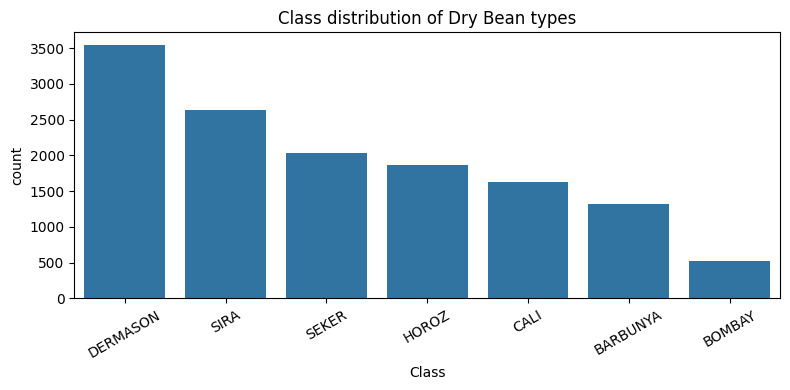

In [6]:
# Count the samples in each class and plot them
import matplotlib.pyplot as plt
import seaborn as sns

counts = df_clean["Class"].value_counts()
percent = (counts / len(df_clean) * 100).round(2)
print(pd.DataFrame({"count": counts, "percent (%)": percent}))
print("\nImbalance ratio (max/min):", round(counts.max() / counts.min(), 2))

plt.figure(figsize=(8, 4))
sns.countplot(data=df_clean, x="Class", order=counts.index)
plt.title("Class distribution of Dry Bean types")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 1.4 Descriptive statistics

The features have very different scales (for example Area and ShapeFactor2), so scaling is needed for Logistic Regression, SVM and the Neural Network.

In [7]:
# Summary statistics of the features
pd.set_option("display.max_columns", None)
df_clean.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
Area,13543.0,53048.460,29392.438,20420.000,36282.500,44580.000,61382.000,254616.000
Perimeter,13543.0,854.993,214.723,524.736,703.230,793.896,977.146,1985.370
MajorAxisLength,13543.0,319.896,85.809,183.601,253.087,296.405,376.312,738.860
MinorAxisLength,13543.0,202.365,45.052,122.513,175.886,192.491,217.245,460.198
AspectRation,13543.0,1.581,0.245,1.025,1.431,1.550,1.704,2.430
Eccentricity,13543.0,0.750,0.092,0.219,0.715,0.764,0.810,0.911
ConvexArea,13543.0,53767.987,29844.249,20684.000,36673.000,45122.000,62360.000,263261.000
EquivDiameter,13543.0,253.034,59.308,161.244,214.933,238.246,279.560,569.374
Extent,13543.0,0.750,0.049,0.555,0.719,0.760,0.787,0.866
Solidity,13543.0,0.987,0.005,0.919,0.986,0.988,0.990,0.995


## 1.5 Outliers

We used the IQR method. Of the 551 Area outliers, 522 are Bombay samples (all of the Bombay class). We kept the outliers because they are real values and they help to separate Bombay from the other classes.

In [8]:
# Count the outliers in each feature (IQR method)
features = df_clean.drop(columns="Class")
Q1 = features.quantile(0.25)
Q3 = features.quantile(0.75)
IQR = Q3 - Q1

mask = (features < Q1 - 1.5 * IQR) | (features > Q3 + 1.5 * IQR)
outlier_counts = mask.sum()
print(pd.DataFrame({
    "outliers": outlier_counts,
    "percent (%)": (outlier_counts / len(df_clean) * 100).round(2)
}))

                 outliers  percent (%)
Area                  551         4.07
Perimeter             500         3.69
MajorAxisLength       379         2.80
MinorAxisLength       567         4.19
AspectRation          485         3.58
Eccentricity          833         6.15
ConvexArea            549         4.05
EquivDiameter         526         3.88
Extent                271         2.00
Solidity              774         5.72
roundness              98         0.72
Compactness           124         0.92
ShapeFactor1          533         3.94
ShapeFactor2            0         0.00
ShapeFactor3          202         1.49
ShapeFactor4          760         5.61


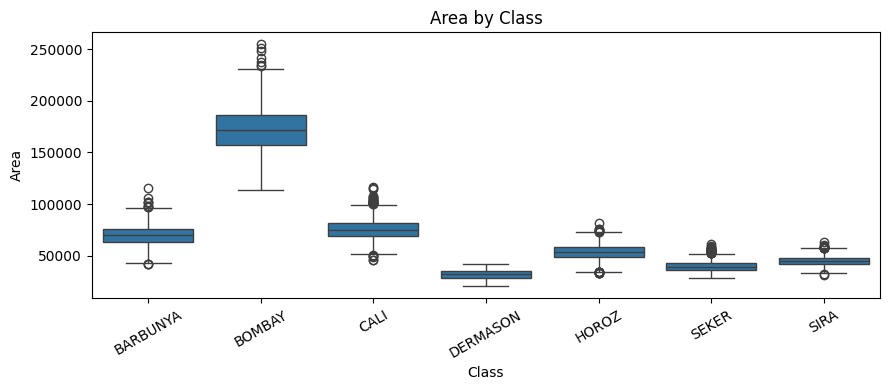

In [9]:
# Boxplot of Area for each class
plt.figure(figsize=(9, 4))
sns.boxplot(data=df_clean, x="Class", y="Area", order=sorted(df_clean["Class"].unique()))
plt.title("Area by Class")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("area_by_class.png", dpi=200)
plt.show()

In [10]:
# Check which classes have the Area outliers
q1, q3 = df_clean["Area"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
area_out = df_clean[df_clean["Area"] > upper]

print("Upper fence:", round(upper))
print(area_out["Class"].value_counts())

Upper fence: 99031
Class
BOMBAY      522
CALI         24
BARBUNYA      5
Name: count, dtype: int64


## 1.6 Correlation

There are two groups of highly correlated features: a size group and a shape group. We kept all 16 features because removing 6 of them did not change the cross-validation results (see the extra analysis at the end).

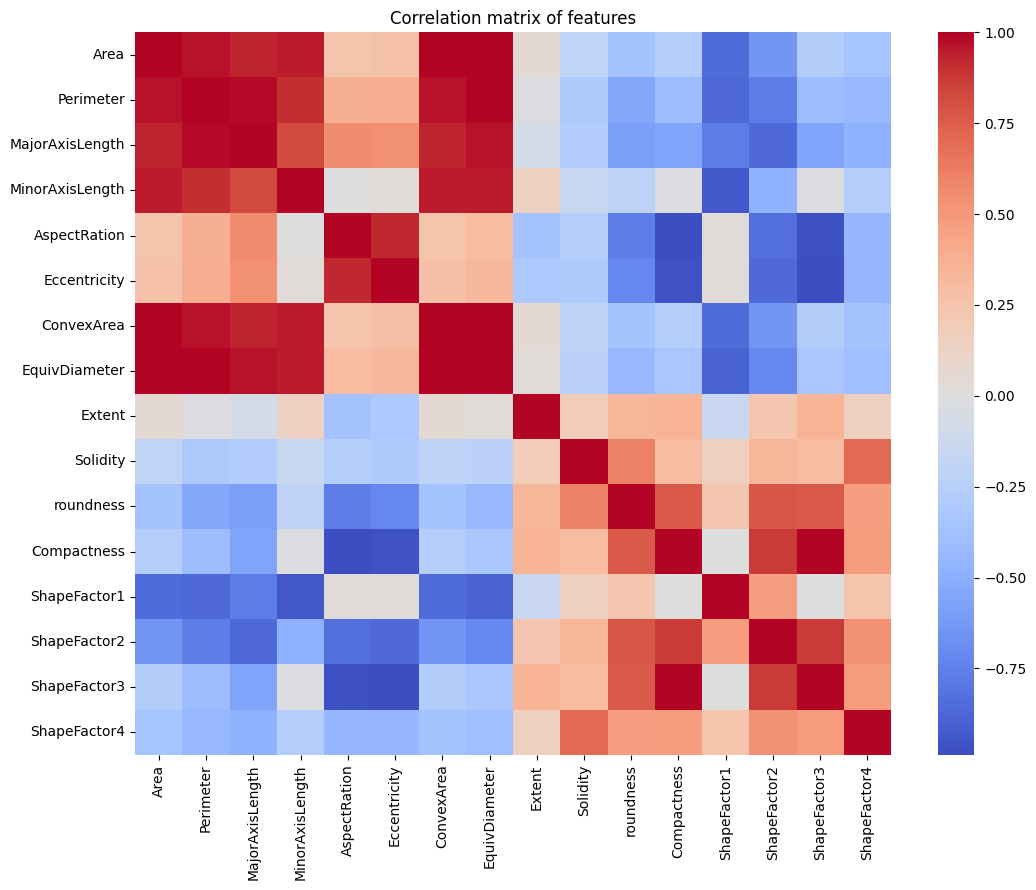

Area             ConvexArea         1.000
Compactness      ShapeFactor3       0.999
Perimeter        EquivDiameter      0.991
ConvexArea       EquivDiameter      0.985
Area             EquivDiameter      0.985
Perimeter        MajorAxisLength    0.978
                 ConvexArea         0.968
Area             Perimeter          0.967
MajorAxisLength  EquivDiameter      0.962
Area             MinorAxisLength    0.952
MinorAxisLength  ConvexArea         0.952
Eccentricity     Compactness       -0.970
AspectRation     ShapeFactor3      -0.979
Eccentricity     ShapeFactor3      -0.981
AspectRation     Compactness       -0.988
dtype: float64


In [11]:
# Correlation between the features
import numpy as np

corr = df_clean.drop(columns="Class").corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Correlation matrix of features")
plt.tight_layout()
plt.show()

upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
high_pairs = upper.stack()
high_pairs = high_pairs[high_pairs.abs() > 0.95].sort_values(ascending=False)
print(high_pairs.round(3))

# Stage 2: Data Splitting
## 2.1 Train / validation / test split

The data is split 70/15/15 into training (9,480), validation (2,031) and test (2,032) sets. The split is stratified with random_state=42, and the class percentages are almost the same in all three sets.

In [12]:
# Encode the target and split the data (70/15/15)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

X = df_clean.drop(columns="Class")
y = df_clean["Class"]

le = LabelEncoder()
y_enc = le.fit_transform(y)
print(dict(zip(le.classes_, range(len(le.classes_)))))

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y_enc, test_size=0.30, stratify=y_enc, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42)

print("Train:", X_train.shape, "| Val:", X_val.shape, "| Test:", X_test.shape)

dist = pd.DataFrame({
    "train %": pd.Series(y_train).value_counts(normalize=True).sort_index() * 100,
    "val %":   pd.Series(y_val).value_counts(normalize=True).sort_index() * 100,
    "test %":  pd.Series(y_test).value_counts(normalize=True).sort_index() * 100,
}).round(2)
dist.index = le.classes_
print(dist)

{'BARBUNYA': 0, 'BOMBAY': 1, 'CALI': 2, 'DERMASON': 3, 'HOROZ': 4, 'SEKER': 5, 'SIRA': 6}
Train: (9480, 16) | Val: (2031, 16) | Test: (2032, 16)
          train %  val %  test %
BARBUNYA     9.76   9.80    9.74
BOMBAY       3.86   3.84    3.84
CALI        12.04  12.01   12.06
DERMASON    26.18  26.19   26.18
HOROZ       13.73  13.74   13.73
SEKER       14.97  14.97   14.96
SIRA        19.46  19.45   19.49


## 2.2 Scaling

StandardScaler is fitted on the training set only and then applied to the validation and test sets, to avoid data leakage.

In [13]:
# Scale the features
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # fit on the training set only
X_val_s   = scaler.transform(X_val)         # apply the same values without fitting
X_test_s  = scaler.transform(X_test)

check = pd.DataFrame({
    "train mean": pd.DataFrame(X_train_s, columns=X.columns).mean(),
    "train std":  pd.DataFrame(X_train_s, columns=X.columns).std(),
    "val mean":   pd.DataFrame(X_val_s, columns=X.columns).mean(),
    "val std":    pd.DataFrame(X_val_s, columns=X.columns).std(),
}).round(3)
print(check)

                 train mean  train std  val mean  val std
Area                    0.0        1.0     0.001    1.012
Perimeter              -0.0        1.0     0.001    1.009
MajorAxisLength        -0.0        1.0     0.001    1.010
MinorAxisLength        -0.0        1.0    -0.003    1.006
AspectRation           -0.0        1.0     0.005    1.002
Eccentricity            0.0        1.0     0.006    0.990
ConvexArea             -0.0        1.0     0.001    1.013
EquivDiameter           0.0        1.0    -0.001    1.009
Extent                  0.0        1.0    -0.030    1.036
Solidity               -0.0        1.0     0.004    0.950
roundness               0.0        1.0    -0.013    0.997
Compactness             0.0        1.0    -0.004    1.000
ShapeFactor1           -0.0        1.0     0.007    1.013
ShapeFactor2           -0.0        1.0    -0.002    0.993
ShapeFactor3            0.0        1.0    -0.004    0.999
ShapeFactor4           -0.0        1.0     0.019    0.925


# Stage 3: Model Selection and Development
We selected four models: Logistic Regression as a simple baseline, SVM with an RBF kernel for non-linear boundaries, Random Forest (it is less sensitive to outliers and correlated features) and a Neural Network (MLP).

# Stage 4: Training and Hyperparameter Optimization
## 4.1 Baseline models (default settings)

Logistic Regression and SVM have a small gap between training and validation accuracy. Random Forest overfits (training accuracy 1.0000 and validation accuracy 0.9207).

In [14]:
# Train the baseline models with default settings
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

results = []

def evaluate(name, model, Xtr, Xv):
    model.fit(Xtr, y_train)
    pred_tr = model.predict(Xtr)
    pred_v = model.predict(Xv)
    results.append({
        "Model": name,
        "Train Acc": accuracy_score(y_train, pred_tr),
        "Val Acc": accuracy_score(y_val, pred_v),
        "Train Macro-F1": f1_score(y_train, pred_tr, average="macro"),
        "Val Macro-F1": f1_score(y_val, pred_v, average="macro"),
    })

evaluate("Logistic Regression", LogisticRegression(max_iter=1000, random_state=42), X_train_s, X_val_s)
evaluate("SVM (RBF)", SVC(random_state=42), X_train_s, X_val_s)
evaluate("Random Forest", RandomForestClassifier(random_state=42), X_train, X_val)

pd.DataFrame(results).round(4)

,Model,Train Acc,Val Acc,Train Macro-F1,Val Macro-F1
0,Logistic Regression,0.9257,0.9202,0.9379,0.9302
1,SVM (RBF),0.9348,0.9281,0.9460,0.9386
2,Random Forest,1.0000,0.9207,1.0000,0.9329


In [15]:
# Add the gap between train and validation accuracy
res = pd.DataFrame(results)
res["Acc Gap"] = res["Train Acc"] - res["Val Acc"]
res.round(4)

,Model,Train Acc,Val Acc,Train Macro-F1,Val Macro-F1,Acc Gap
0,Logistic Regression,0.9257,0.9202,0.9379,0.9302,0.0055
1,SVM (RBF),0.9348,0.9281,0.9460,0.9386,0.0067
2,Random Forest,1.0000,0.9207,1.0000,0.9329,0.0793


## 4.2 Neural Network (first version)

The first network has the structure 16 → 64 → 32 → 7 (3,399 parameters). Its validation loss stops improving early and then rises slowly, which shows mild overfitting.

In [16]:
# Build and train the first Neural Network
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.keras.utils.set_random_seed(42)

model = keras.Sequential([
    layers.Input(shape=(16,)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(7, activation="softmax"),
])

model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

model.summary()

history = model.fit(X_train_s, y_train,
                    validation_data=(X_val_s, y_val),
                    epochs=60, batch_size=32, verbose=0)

print("Final train acc:", round(history.history["accuracy"][-1], 4))
print("Final val acc  :", round(history.history["val_accuracy"][-1], 4))

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,399 (13.28 KB)

 Trainable params: 3,399 (13.28 KB)

 Non-trainable params: 0 (0.00 B)

Final train acc: 0.9416
Final val acc  : 0.9247


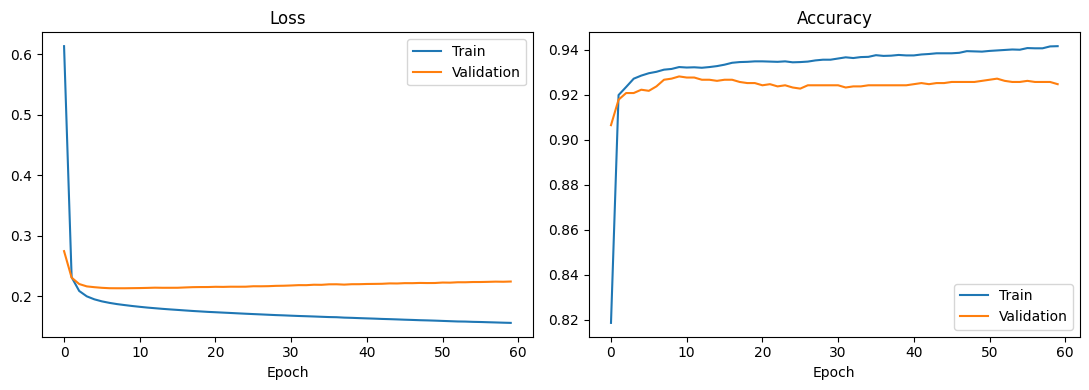

In [17]:
# Plot the training and validation curves
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].plot(history.history["loss"], label="Train")
ax[0].plot(history.history["val_loss"], label="Validation")
ax[0].set_title("Loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()

ax[1].plot(history.history["accuracy"], label="Train")
ax[1].plot(history.history["val_accuracy"], label="Validation")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("Epoch"); ax[1].legend()

plt.tight_layout()
plt.show()

In [18]:
# Find the epoch with the lowest validation loss (first Neural Network)
h1 = history.history   # history = the first Neural Network (not history2)

best_ep = int(np.argmin(h1["val_loss"]))
print("Lowest val loss at epoch (counting from 0):", best_ep, "| (counting from 1):", best_ep + 1)
print("Lowest val loss:", round(min(h1["val_loss"]), 4))
print("Final train acc:", round(h1["accuracy"][-1], 4))
print("Final val acc  :", round(h1["val_accuracy"][-1], 4))

Lowest val loss at epoch (counting from 0): 8 | (counting from 1): 9
Lowest val loss: 0.2135
Final train acc: 0.9416
Final val acc  : 0.9247


## 4.3 Neural Network with Dropout and Early Stopping

We added Dropout (0.2) and Early Stopping (patience 10). The training and validation curves are closer now, but the accuracy did not improve much.

In [19]:
# Neural Network with Dropout and Early Stopping
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)

model2 = keras.Sequential([
    layers.Input(shape=(16,)),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(7, activation="softmax"),
])

model2.compile(optimizer="adam",
               loss="sparse_categorical_crossentropy",
               metrics=["accuracy"])

early_stop = EarlyStopping(monitor="val_loss", patience=10,
                           restore_best_weights=True)

history2 = model2.fit(X_train_s, y_train,
                      validation_data=(X_val_s, y_val),
                      epochs=100, batch_size=32,
                      callbacks=[early_stop], verbose=0)

print("Stopped after epochs:", len(history2.history["loss"]))
print("Best val loss:", round(min(history2.history["val_loss"]), 4))
tr_loss, tr_acc = model2.evaluate(X_train_s, y_train, verbose=0)
va_loss, va_acc = model2.evaluate(X_val_s, y_val, verbose=0)
print("Train acc:", round(tr_acc, 4), "| Val acc:", round(va_acc, 4))

Stopped after epochs: 30
Best val loss: 0.2113
Train acc: 0.9359 | Val acc: 0.9276


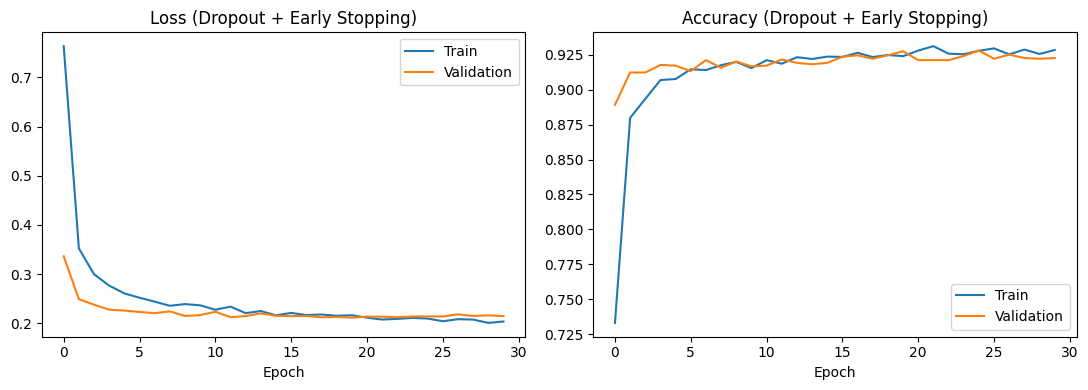

In [20]:
# Plot the curves again
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].plot(history2.history["loss"], label="Train")
ax[0].plot(history2.history["val_loss"], label="Validation")
ax[0].set_title("Loss (Dropout + Early Stopping)"); ax[0].set_xlabel("Epoch"); ax[0].legend()

ax[1].plot(history2.history["accuracy"], label="Train")
ax[1].plot(history2.history["val_accuracy"], label="Validation")
ax[1].set_title("Accuracy (Dropout + Early Stopping)"); ax[1].set_xlabel("Epoch"); ax[1].legend()

plt.tight_layout()
plt.show()

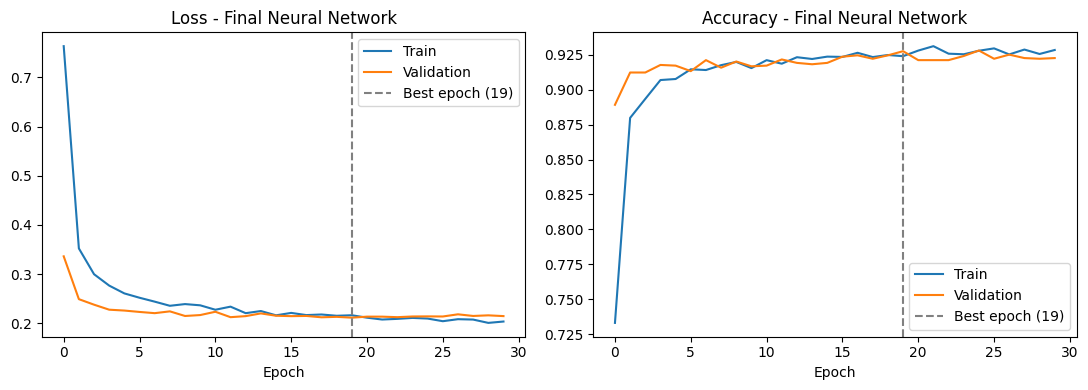

In [21]:
# Code to plot the final Neural Network training curves and mark the best epoch (Figure 8)
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

# Plot Final Training and Validation Loss
ax[0].plot(history2.history["loss"], label="Train")
ax[0].plot(history2.history["val_loss"], label="Validation")

# Calculate the best epoch based on the lowest validation loss
best_epoch = int(np.argmin(history2.history["val_loss"]))
ax[0].axvline(x=best_epoch, color="gray", linestyle="--", label=f"Best epoch ({best_epoch})")
ax[0].set_title("Loss - Final Neural Network")
ax[0].set_xlabel("Epoch")
ax[0].legend()

# Plot Final Training and Validation Accuracy with the best epoch line
ax[1].plot(history2.history["accuracy"], label="Train")
ax[1].plot(history2.history["val_accuracy"], label="Validation")
ax[1].axvline(x=best_epoch, color="gray", linestyle="--", label=f"Best epoch ({best_epoch})")
ax[1].set_title("Accuracy - Final Neural Network")
ax[1].set_xlabel("Epoch")
ax[1].legend()

plt.tight_layout()
plt.show()

## 4.4 Hyperparameter tuning
### Random Forest

We used 5-fold cross-validation on the training set. The best settings are 200 trees, max_depth 12 and min_samples_leaf 1. The overfitting decreased a little, but the validation score did not change much.

In [22]:
# Tune Random Forest with GridSearchCV
from sklearn.model_selection import GridSearchCV, StratifiedKFold

param_grid = {
    "n_estimators": [200, 400],
    "max_depth": [8, 12, 20, None],
    "min_samples_leaf": [1, 3, 5],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_rf = GridSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    param_grid, cv=cv, scoring="f1_macro", n_jobs=-1, verbose=1)

grid_rf.fit(X_train, y_train)

print("Best params:", grid_rf.best_params_)
print("Best CV macro-F1:", round(grid_rf.best_score_, 4))

best_rf = grid_rf.best_estimator_
pred_tr = best_rf.predict(X_train)
pred_v = best_rf.predict(X_val)
print("Train acc:", round(accuracy_score(y_train, pred_tr), 4),
      "| Val acc:", round(accuracy_score(y_val, pred_v), 4))
print("Train F1 :", round(f1_score(y_train, pred_tr, average="macro"), 4),
      "| Val F1 :", round(f1_score(y_val, pred_v, average="macro"), 4))

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best params: {'max_depth': 12, 'min_samples_leaf': 1, 'n_estimators': 200}
Best CV macro-F1: 0.9366
Train acc: 0.9869 | Val acc: 0.9217
Train F1 : 0.9892 | Val F1 : 0.9325


### SVM

Best settings: C = 10 and gamma = scale. The tuning did not improve the validation score much.

In [23]:
# Tune SVM with GridSearchCV
from sklearn.pipeline import Pipeline

pipe_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(random_state=42)),
])

param_grid_svm = {
    "svc__C": [1, 10, 100],
    "svc__gamma": ["scale", 0.01, 0.1],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_svm = GridSearchCV(pipe_svm, param_grid_svm, cv=cv,
                        scoring="f1_macro", n_jobs=-1, verbose=1)
grid_svm.fit(X_train, y_train)   # unscaled X_train: the scaler is inside the pipeline

print("Best params:", grid_svm.best_params_)
print("Best CV macro-F1:", round(grid_svm.best_score_, 4))

best_svm = grid_svm.best_estimator_
pred_tr = best_svm.predict(X_train)
pred_v = best_svm.predict(X_val)
print("Train acc:", round(accuracy_score(y_train, pred_tr), 4),
      "| Val acc:", round(accuracy_score(y_val, pred_v), 4))
print("Train F1 :", round(f1_score(y_train, pred_tr, average="macro"), 4),
      "| Val F1 :", round(f1_score(y_val, pred_v, average="macro"), 4))

Fitting 5 folds for each of 9 candidates, totalling 45 fits
Best params: {'svc__C': 10, 'svc__gamma': 'scale'}
Best CV macro-F1: 0.944
Train acc: 0.9407 | Val acc: 0.9281
Train F1 : 0.9518 | Val F1 : 0.9381


### Logistic Regression

Best setting: C = 1, which is the default value, so the validation score stayed the same.

In [24]:
# Tune Logistic Regression with GridSearchCV
pipe_lr = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LogisticRegression(max_iter=2000, random_state=42)),
])

param_grid_lr = {"lr__C": [0.01, 0.1, 1, 10, 100]}

grid_lr = GridSearchCV(pipe_lr, param_grid_lr, cv=cv,
                       scoring="f1_macro", n_jobs=-1, verbose=1)
grid_lr.fit(X_train, y_train)

print("Best params:", grid_lr.best_params_)
print("Best CV macro-F1:", round(grid_lr.best_score_, 4))

best_lr = grid_lr.best_estimator_
pred_tr = best_lr.predict(X_train)
pred_v = best_lr.predict(X_val)
print("Train acc:", round(accuracy_score(y_train, pred_tr), 4),
      "| Val acc:", round(accuracy_score(y_val, pred_v), 4))
print("Train F1 :", round(f1_score(y_train, pred_tr, average="macro"), 4),
      "| Val F1 :", round(f1_score(y_val, pred_v, average="macro"), 4))

Fitting 5 folds for each of 5 candidates, totalling 25 fits
Best params: {'lr__C': 1}
Best CV macro-F1: 0.937
Train acc: 0.9257 | Val acc: 0.9202
Train F1 : 0.9379 | Val F1 : 0.9302


### Neural Network

We compared 12 settings (network size, dropout and learning rate) on the validation set. All of them gave similar results. We chose (64, 32) units, dropout 0.2 and learning rate 0.001.

In [25]:
# Try 12 Neural Network settings and keep the best one
import itertools
from sklearn.metrics import f1_score

configs = list(itertools.product(
    [(32, 16), (64, 32), (128, 64)],   # hidden units
    [0.2, 0.3],                        # dropout
    [0.001, 0.003],                    # learning rate
))

def build_model(units, dropout, lr):
    m = keras.Sequential([
        layers.Input(shape=(16,)),
        layers.Dense(units[0], activation="relu"),
        layers.Dropout(dropout),
        layers.Dense(units[1], activation="relu"),
        layers.Dropout(dropout),
        layers.Dense(7, activation="softmax"),
    ])
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

nn_results = []
best_f1, best_nn, best_hist = -1, None, None

for units, dropout, lr in configs:
    keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)
    m = build_model(units, dropout, lr)
    es = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
    h = m.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
              epochs=100, batch_size=32, callbacks=[es], verbose=0)

    val_pred = np.argmax(m.predict(X_val_s, verbose=0), axis=1)
    tr_pred = np.argmax(m.predict(X_train_s, verbose=0), axis=1)
    f1_v = f1_score(y_val, val_pred, average="macro")
    nn_results.append({
        "Units": units, "Dropout": dropout, "LR": lr,
        "Epochs": len(h.history["loss"]),
        "Train Acc": accuracy_score(y_train, tr_pred),
        "Val Acc": accuracy_score(y_val, val_pred),
        "Train Macro-F1": f1_score(y_train, tr_pred, average="macro"),
        "Val Macro-F1": f1_v,
    })
    if f1_v > best_f1:
        best_f1, best_nn, best_hist = f1_v, m, h

nn_df = pd.DataFrame(nn_results).sort_values("Val Macro-F1", ascending=False)

# Train Macro-F1 of the selected (best) Neural Network
best_tr_pred = np.argmax(best_nn.predict(X_train_s, verbose=0), axis=1)
print("Best NN - Train Macro-F1:", round(f1_score(y_train, best_tr_pred, average="macro"), 4))

nn_df.round(4)

Best NN - Train Macro-F1: 0.9463


,Units,Dropout,LR,Epochs,Train Acc,Val Acc,Train Macro-F1,Val Macro-F1
4,"(64, 32)",0.2,0.001,30,0.9359,0.9276,0.9463,0.9372
8,"(128, 64)",0.2,0.001,40,0.9398,0.9281,0.9501,0.9369
11,"(128, 64)",0.3,0.003,26,0.9338,0.9291,0.9445,0.9366
9,"(128, 64)",0.2,0.003,21,0.9346,0.9261,0.9454,0.9359
10,"(128, 64)",0.3,0.001,26,0.9359,0.9247,0.9461,0.9343
0,"(32, 16)",0.2,0.001,51,0.9351,0.9237,0.9459,0.9343
7,"(64, 32)",0.3,0.003,32,0.9354,0.9227,0.9460,0.9341
2,"(32, 16)",0.3,0.001,51,0.9324,0.9227,0.9430,0.9335
1,"(32, 16)",0.2,0.003,28,0.9320,0.9237,0.9427,0.9330
6,"(64, 32)",0.3,0.001,32,0.9351,0.9222,0.9451,0.9330


### Best Neural Network: training and validation curves

The best epoch is 19 (counting from 0). The training and validation curves stay close to each other, so there is no clear overfitting.

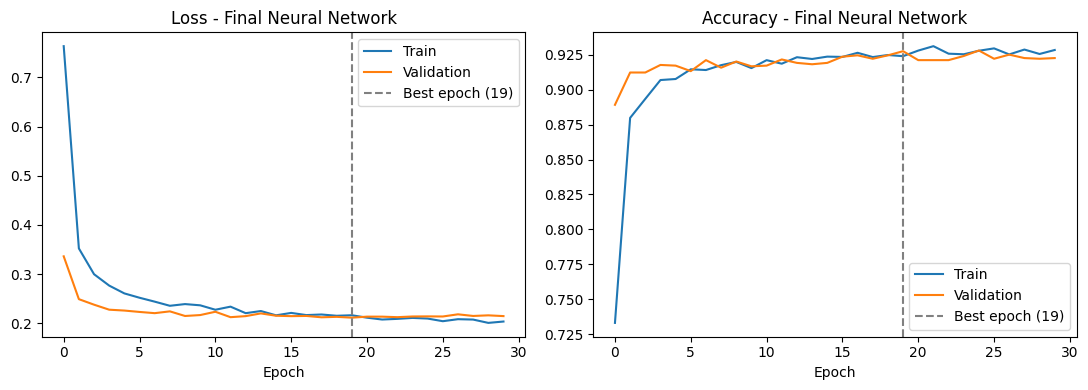

Best epoch: 19 | Best val loss: 0.2113


In [26]:
# Plot the curves of the best Neural Network
h = best_hist.history
best_epoch = int(np.argmin(h["val_loss"]))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].plot(h["loss"], label="Train")
ax[0].plot(h["val_loss"], label="Validation")
ax[0].axvline(best_epoch, color="gray", linestyle="--", label=f"Best epoch ({best_epoch})")
ax[0].set_title("Loss - Final Neural Network")
ax[0].set_xlabel("Epoch"); ax[0].legend()

ax[1].plot(h["accuracy"], label="Train")
ax[1].plot(h["val_accuracy"], label="Validation")
ax[1].axvline(best_epoch, color="gray", linestyle="--", label=f"Best epoch ({best_epoch})")
ax[1].set_title("Accuracy - Final Neural Network")
ax[1].set_xlabel("Epoch"); ax[1].legend()

plt.tight_layout()
plt.savefig("nn_curves_final.png", dpi=150)
plt.show()

print("Best epoch:", best_epoch, "| Best val loss:", round(min(h["val_loss"]), 4))

# Stage 5: Model Evaluation and Comparison
## 5.1 Test set results

SVM has the highest test Macro-F1 (0.9361), followed by the Neural Network (0.9352), Logistic Regression (0.9347) and Random Forest (0.9307). The differences between the models are very small.

In [27]:
# Evaluate all models on the test set
from sklearn.metrics import precision_score, recall_score

test_results = []
preds = {}

def test_eval(name, y_pred):
    preds[name] = y_pred
    test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro Precision": precision_score(y_test, y_pred, average="macro"),
        "Macro Recall": recall_score(y_test, y_pred, average="macro"),
        "Macro-F1": f1_score(y_test, y_pred, average="macro"),
    })

test_eval("Logistic Regression", best_lr.predict(X_test))
test_eval("SVM (RBF)", best_svm.predict(X_test))
test_eval("Random Forest", best_rf.predict(X_test))
test_eval("Neural Network", np.argmax(best_nn.predict(X_test_s, verbose=0), axis=1))

pd.DataFrame(test_results).sort_values("Macro-F1", ascending=False).round(4)

,Model,Accuracy,Macro Precision,Macro Recall,Macro-F1
1,SVM (RBF),0.9232,0.9360,0.9362,0.9361
3,Neural Network,0.9222,0.9359,0.9347,0.9352
0,Logistic Regression,0.9218,0.9349,0.9347,0.9347
2,Random Forest,0.9168,0.9309,0.9306,0.9307


## 5.2 SVM confusion matrix and classification report

Bombay is classified perfectly. Most of the errors are between Dermason and Sira.

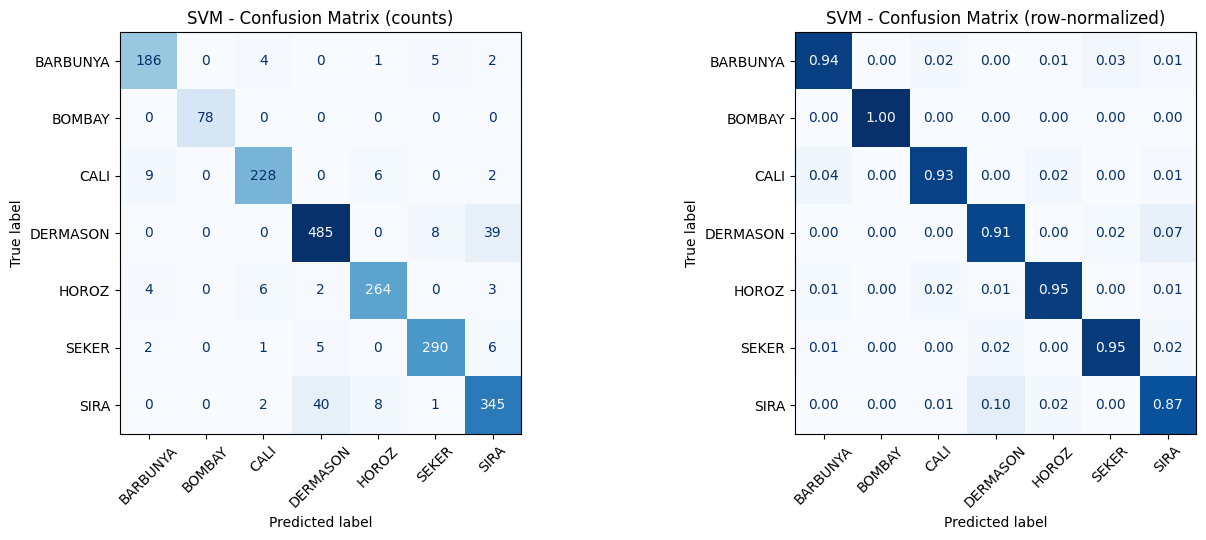

              precision    recall  f1-score   support

    BARBUNYA      0.925     0.939     0.932       198
      BOMBAY      1.000     1.000     1.000        78
        CALI      0.946     0.931     0.938       245
    DERMASON      0.912     0.912     0.912       532
       HOROZ      0.946     0.946     0.946       279
       SEKER      0.954     0.954     0.954       304
        SIRA      0.869     0.871     0.870       396

    accuracy                          0.923      2032
   macro avg      0.936     0.936     0.936      2032
weighted avg      0.923     0.923     0.923      2032



In [28]:
# Confusion matrix and report for the SVM
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

y_pred_svm = preds["SVM (RBF)"]

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_svm, display_labels=le.classes_,
    cmap="Blues", ax=ax[0], xticks_rotation=45, colorbar=False)
ax[0].set_title("SVM - Confusion Matrix (counts)")

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_svm, display_labels=le.classes_,
    normalize="true", values_format=".2f",
    cmap="Blues", ax=ax[1], xticks_rotation=45, colorbar=False)
ax[1].set_title("SVM - Confusion Matrix (row-normalized)")

plt.tight_layout()
plt.savefig("svm_confusion_matrix.png", dpi=150)
plt.show()

print(classification_report(y_test, y_pred_svm, target_names=le.classes_, digits=3))

## 5.3 Confusion matrices of all models and Dermason vs Sira

All four models make the same kind of errors, mainly between Dermason and Sira. The table at the end of the next cell shows how different the two classes are in each feature (in standard deviations).

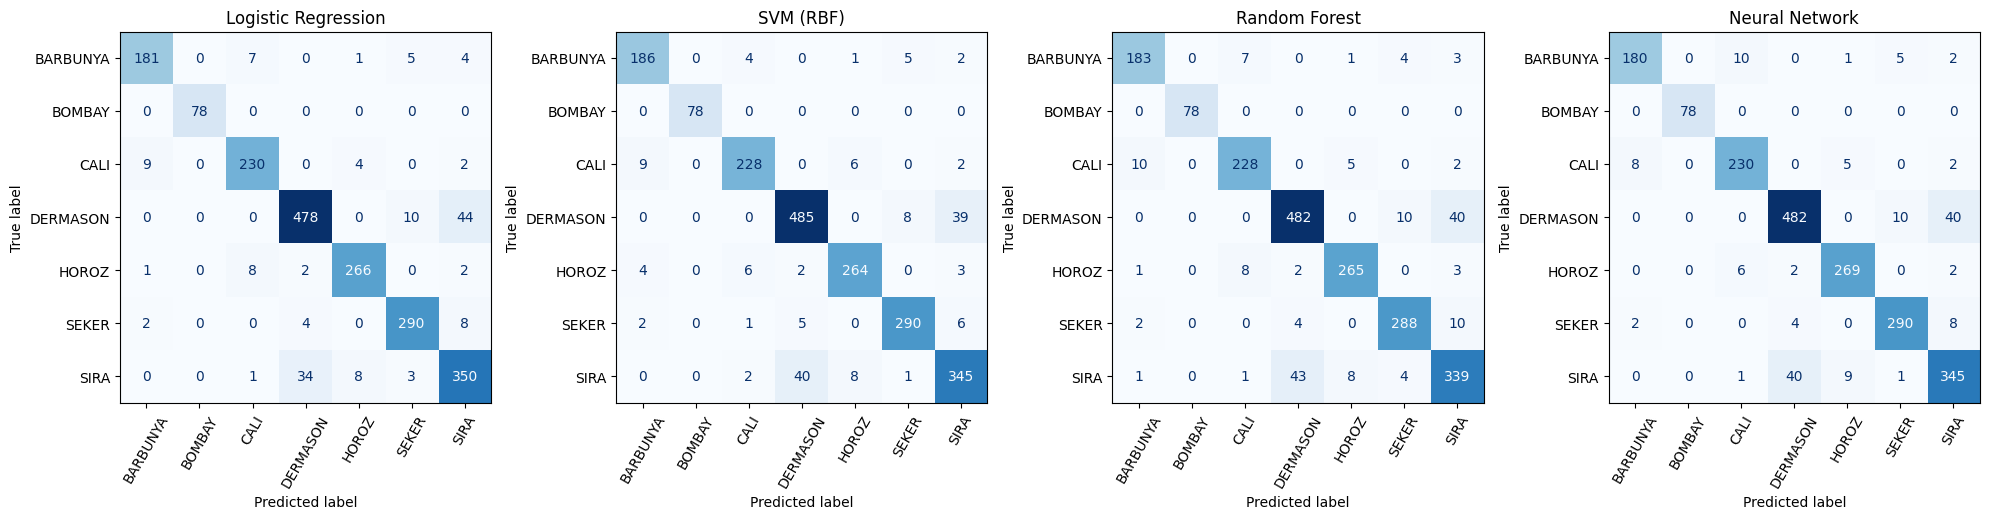

Extent             0.09
Solidity           0.09
ShapeFactor4       0.64
Eccentricity       0.76
AspectRation       0.76
Compactness        0.78
ShapeFactor3       0.78
roundness          0.79
ShapeFactor2       1.38
ShapeFactor1       1.45
MinorAxisLength    1.50
MajorAxisLength    1.58
EquivDiameter      1.61
Area               1.62
Perimeter          1.63
ConvexArea         1.63
dtype: float64


In [29]:
# 1) Confusion matrices for all four models
fig, ax = plt.subplots(1, 4, figsize=(20, 5))
for a, (name, p) in zip(ax, preds.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, p, display_labels=le.classes_, cmap="Blues",
        ax=a, xticks_rotation=60, colorbar=False)
    a.set_title(name)
plt.tight_layout()
plt.savefig("all_confusion_matrices.png", dpi=150)
plt.show()

# 2) Mean difference between Dermason and Sira per feature (in std units)
pair = df_clean[df_clean["Class"].isin(["DERMASON", "SIRA"])]
means = pair.groupby("Class").mean()
gap = (means.loc["SIRA"] - means.loc["DERMASON"]) / pair.drop(columns="Class").std()
print(gap.abs().sort_values().round(2))

### Confusion matrices (2x2 layout)

The same matrices in a 2x2 layout, used in the report.

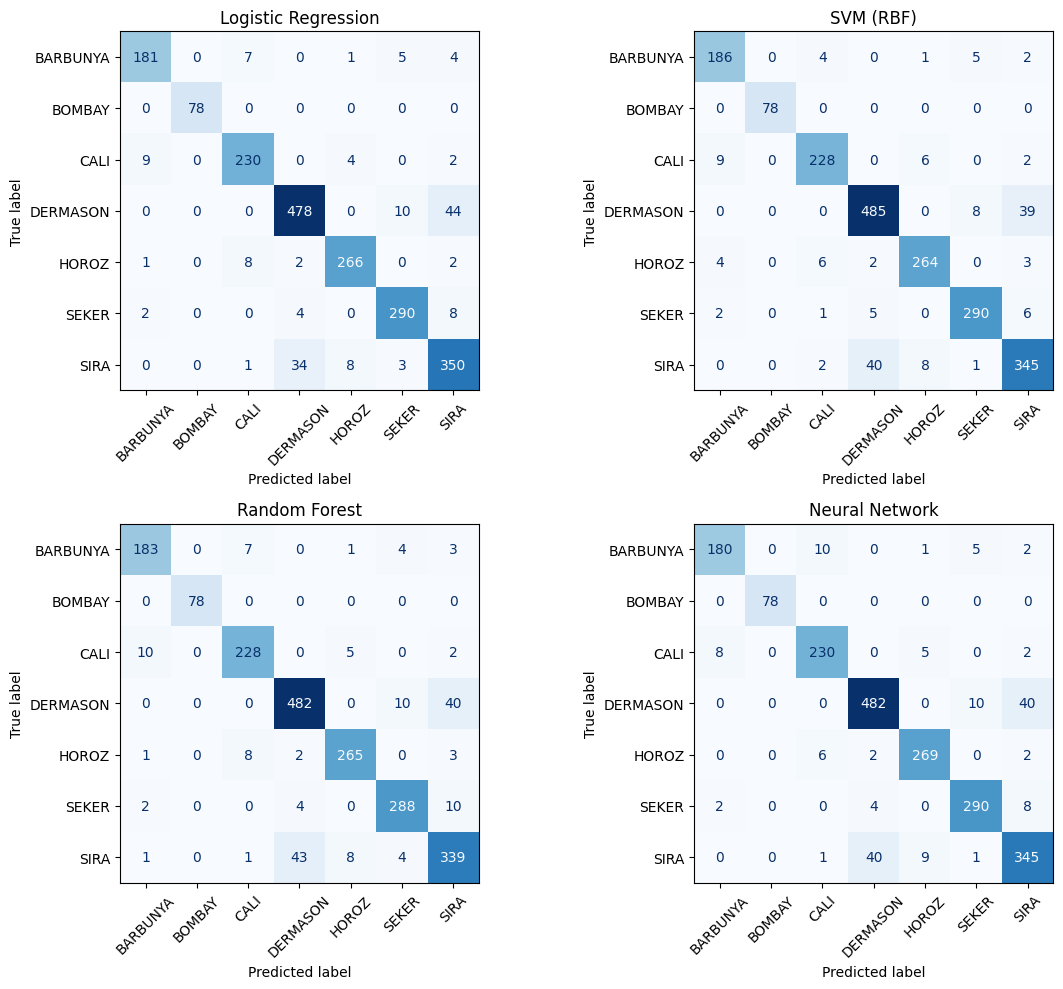

In [30]:
# Confusion matrices in a 2x2 layout
fig, ax = plt.subplots(2, 2, figsize=(12, 10))
for a, (name, p) in zip(ax.ravel(), preds.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, p, display_labels=le.classes_, cmap="Blues",
        ax=a, xticks_rotation=45, colorbar=False)
    a.set_title(name)
plt.tight_layout()
plt.savefig("all_confusion_matrices_2x2.png", dpi=200)
plt.show()

## 5.4 Dermason/Sira errors and per-class F1

The Dermason and Sira confusion is about half of all errors in every model (78 to 83 samples). Sira has the lowest F1 for all models, and Bombay has an F1 of 1.000 for all models.

In [31]:
# 1) Save the final comparison table
final = pd.DataFrame(test_results).sort_values("Macro-F1", ascending=False).round(4)
final.to_csv("final_comparison.csv", index=False)

# 2) Dermason/Sira confusion counts per model
d = le.transform(["DERMASON"])[0]
s = le.transform(["SIRA"])[0]
for name, p in preds.items():
    d2s = int(((y_test == d) & (p == s)).sum())
    s2d = int(((y_test == s) & (p == d)).sum())
    print(f"{name}: Dermason->Sira = {d2s}, Sira->Dermason = {s2d}, total = {d2s + s2d}")

# 3) Per-class F1 for each model
per_class_f1 = pd.DataFrame(
    {name: f1_score(y_test, p, average=None) for name, p in preds.items()},
    index=le.classes_).round(3)
per_class_f1

Logistic Regression: Dermason->Sira = 44, Sira->Dermason = 34, total = 78
SVM (RBF): Dermason->Sira = 39, Sira->Dermason = 40, total = 79
Random Forest: Dermason->Sira = 40, Sira->Dermason = 43, total = 83
Neural Network: Dermason->Sira = 40, Sira->Dermason = 40, total = 80


,Logistic Regression,SVM (RBF),Random Forest,Neural Network
BARBUNYA,0.926,0.932,0.927,0.928
BOMBAY,1.000,1.000,1.000,1.000
CALI,0.937,0.938,0.933,0.935
DERMASON,0.910,0.912,0.907,0.909
HOROZ,0.953,0.946,0.950,0.956
SEKER,0.948,0.954,0.944,0.951
SIRA,0.868,0.870,0.855,0.868


# Extra analysis
## Do the redundant features matter? (16 vs 10 features)

We compared the 16 features with 10 features (without ConvexArea, EquivDiameter, Perimeter, ShapeFactor3, Eccentricity and Compactness) using cross-validation. The differences are smaller than or similar to the standard deviation between folds, so we kept all 16 features.

In [32]:
# Compare 16 features with 10 features (cross-validation)
from sklearn.model_selection import cross_val_score

drop_cols = ["ConvexArea", "EquivDiameter", "Perimeter",
             "ShapeFactor3", "Eccentricity", "Compactness"]
reduced_cols = [c for c in X_train.columns if c not in drop_cols]
print(len(reduced_cols), "features kept:", reduced_cols)

models = {
    "Logistic Regression": Pipeline([("sc", StandardScaler()),
        ("m", LogisticRegression(C=1, max_iter=2000, random_state=42))]),
    "SVM (RBF)": Pipeline([("sc", StandardScaler()),
        ("m", SVC(C=10, gamma="scale", random_state=42))]),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, max_depth=12, min_samples_leaf=1, random_state=42),
}

rows = []
for name, m in models.items():
    full = cross_val_score(m, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1)
    red = cross_val_score(m, X_train[reduced_cols], y_train, cv=cv, scoring="f1_macro", n_jobs=-1)
    rows.append({"Model": name,
                 "16 features": full.mean(), "std (16)": full.std(),
                 "10 features": red.mean(), "std (10)": red.std(),
                 "Difference": red.mean() - full.mean()})

pd.DataFrame(rows).round(4)

10 features kept: ['Area', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Extent', 'Solidity', 'roundness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor4']


,Model,16 features,std (16),10 features,std (10),Difference
0,Logistic Regression,0.9370,0.0019,0.9368,0.0029,-0.0002
1,SVM (RBF),0.9440,0.0033,0.9438,0.0041,-0.0002
2,Random Forest,0.9366,0.0013,0.9379,0.0022,0.0013


## Feature importance (run after Random Forest tuning)

Random Forest importance and permutation importance (on the validation set) give different rankings, because the features are correlated. In the permutation method, roundness and ShapeFactor4 are the most important.

                 RF importance  Permutation (val)
ShapeFactor3            0.0961             0.0008
Compactness             0.0915             0.0016
MinorAxisLength         0.0895             0.0016
Perimeter               0.0860             0.0071
ShapeFactor1            0.0835             0.0023
MajorAxisLength         0.0801             0.0011
ConvexArea              0.0765            -0.0006
Eccentricity            0.0657            -0.0013
AspectRation            0.0623            -0.0002
Area                    0.0586            -0.0007
EquivDiameter           0.0559             0.0009
roundness               0.0549             0.0657
ShapeFactor2            0.0449            -0.0001
ShapeFactor4            0.0296             0.0342
Solidity                0.0166             0.0028
Extent                  0.0082             0.0012


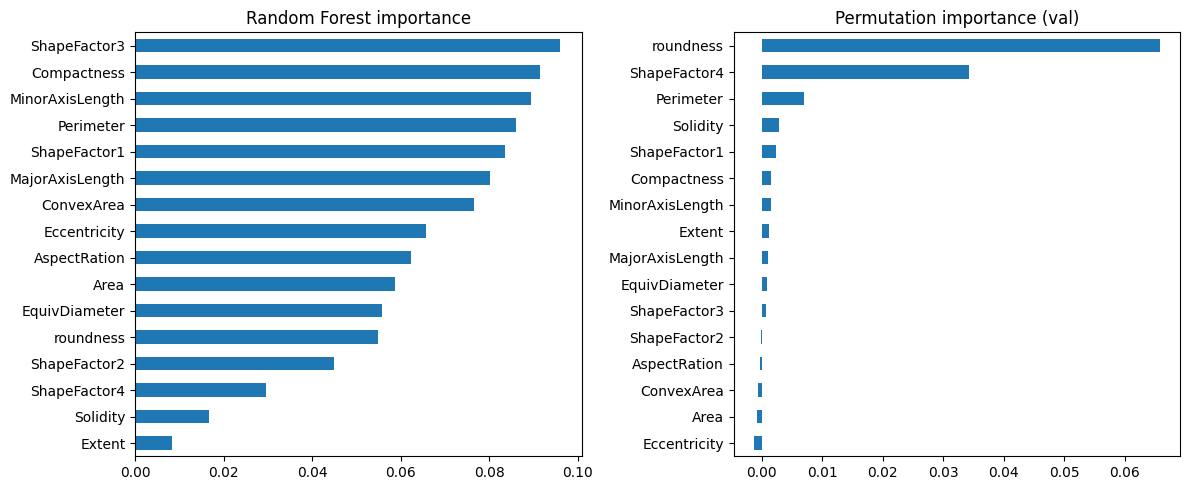

In [33]:
from sklearn.inspection import permutation_importance

# 1) Random Forest importance (trained on the training set)
rf_imp = pd.Series(best_rf.feature_importances_,
                   index=X_train.columns).sort_values(ascending=False)

# 2) Permutation importance on the validation set
perm = permutation_importance(best_rf, X_val, y_val, scoring="f1_macro",
                              n_repeats=10, random_state=42, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean,
                     index=X_train.columns).sort_values(ascending=False)

imp_table = pd.DataFrame({"RF importance": rf_imp, "Permutation (val)": perm_imp}).round(4)
print(imp_table.sort_values("RF importance", ascending=False))

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
rf_imp.sort_values().plot(kind="barh", ax=ax[0]); ax[0].set_title("Random Forest importance")
perm_imp.sort_values().plot(kind="barh", ax=ax[1]); ax[1].set_title("Permutation importance (val)")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=200)
plt.show()

### Top 4 features by class

Size features separate Bombay from the other classes, and shape features show differences between Seker, Horoz and Cali.

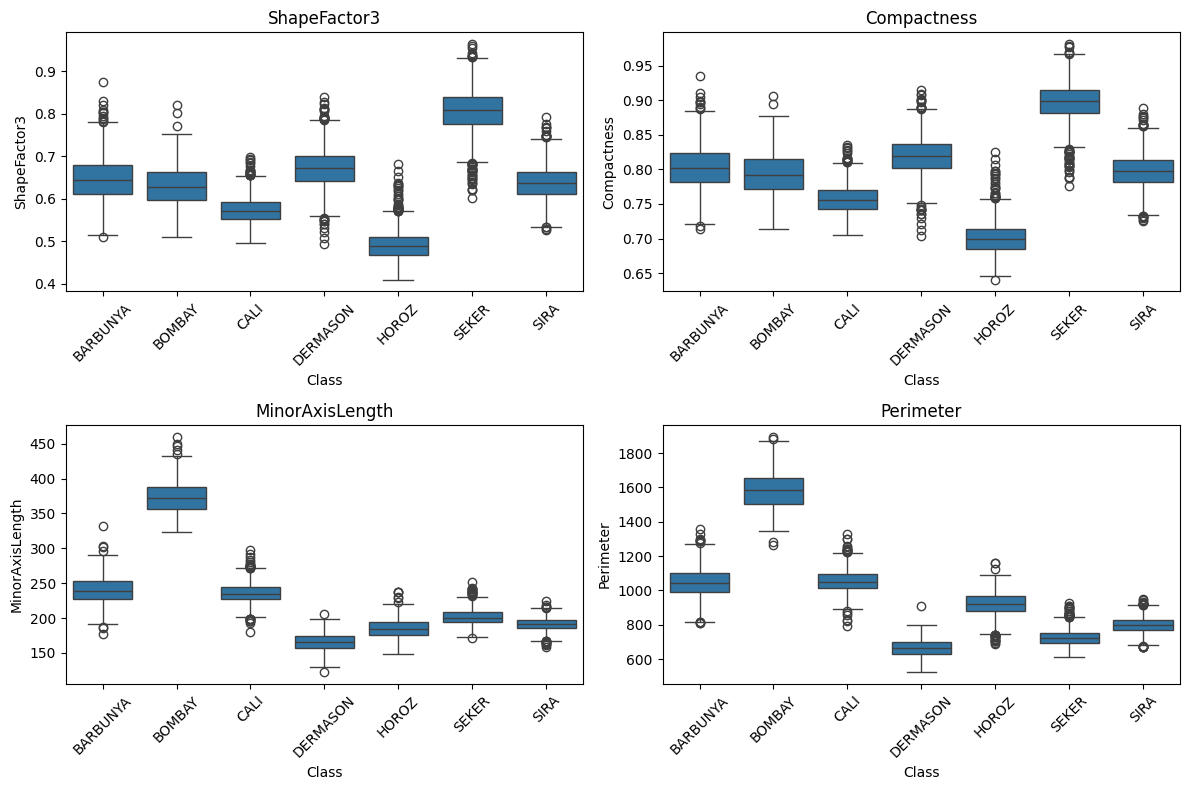

In [34]:
# Boxplots of the top 4 features by class
train_df = X_train.copy()
train_df["Class"] = le.inverse_transform(y_train)

top4 = rf_imp.index[:4]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for a, f in zip(axes.ravel(), top4):
    sns.boxplot(data=train_df, x="Class", y=f, order=sorted(train_df["Class"].unique()), ax=a)
    a.set_title(f); a.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig("top_features_by_class.png", dpi=200)
plt.show()